# Efficiency Analysis: Flow Matching (FM) vs Wavelet Flow Matching (WFM)

This notebook loads per-step, per-epoch, and GPU-memory timing CSVs for one or
more model variants, then produces publication-quality comparison plots.

**Folder structure expected:**
```
data/
├── epoch/   <model_name>_epoch_times.csv    cols: epoch, epoch_time_sec, samples_per_sec
├── steps/   <model_name>_step_times.csv     cols: global_step, step_time_sec, samples_per_sec
└── gpu/     <model_name>_gpu_memory.csv     cols: global_step (or epoch), gpu_memory_gb
```


In [14]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

%matplotlib inline
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 160,
    "font.family": "sans-serif",
    "axes.spines.top": False,
    "axes.spines.right": False,
})


---
## ① Configuration — set your model names and data folders here


In [19]:
# ── USER CONFIGURATION ────────────────────────────────────────────────────────

# Root folder that contains the three sub-folders
DATA_ROOT = Path("/Users/gabrieleaccarino/Workspace/waveletflux/performance/rayleigh_benard")

# Sub-folder names
EPOCH_DIR = DATA_ROOT / "epoch"
STEP_DIR  = DATA_ROOT / "steps"
GPU_DIR   = DATA_ROOT / "gpu"

# Model registry
# Each entry:  display_label -> file_prefix  (the <model_name> part of the filename)
# Add / remove models freely; the notebook adapts automatically.
MODELS = {
    "FM_pixel"      : "FM",
    "WFM 1-scale"   : "WFM1",
    "WFM 3-scales"  : "WFM3",
    # "My new model":   "my_model",   # ← add more rows here
}

# Colour palette — one colour per model key (must match MODELS keys)
PALETTE = {
    "FM_pixel"      : "#E05C5C",
    "WFM 1-scale"   : "#3A7FD5",
    "WFM 3-scales"  : "#2DBF8A",
}

# Warm-up steps to exclude from steady-state stats (set to 0 to include all)
WARMUP_STEPS = 1

# Output filename for the saved figure
OUT_FIG = "efficiency_analysis.png"


---
## ② File discovery & loading


In [20]:
def _load_csv(path: Path) -> pd.DataFrame | None:
    """Load a CSV; return None (with a warning) if the file is missing."""
    if not path.exists():
        print(f"  [skip]  {path} not found")
        return None
    df = pd.read_csv(path)
    print(f"  [ok]    {path}  →  {len(df)} rows  |  cols: {list(df.columns)}")
    return df


def load_all_models(models: dict, epoch_dir, step_dir, gpu_dir) -> dict:
    """
    Returns a nested dict:
        data[label] = {
            "step":  DataFrame or None,
            "epoch": DataFrame or None,
            "gpu":   DataFrame or None,
        }
    """
    data = {}
    for label, prefix in models.items():
        print(f"\n── {label}  (prefix = '{prefix}') ──────────────────────────")
        data[label] = {
            "step":  _load_csv(step_dir  / f"{prefix}_step_times.csv"),
            "epoch": _load_csv(epoch_dir / f"{prefix}_epoch_times.csv"),
            "gpu":   _load_csv(gpu_dir   / f"{prefix}_gpu_memory.csv"),
        }
    return data


print("Loading model data …")
DATA = load_all_models(MODELS, EPOCH_DIR, STEP_DIR, GPU_DIR)


Loading model data …

── FM_pixel  (prefix = 'FM') ──────────────────────────
  [ok]    /Users/gabrieleaccarino/Workspace/waveletflux/performance/rayleigh_benard/steps/FM_step_times.csv  →  220000 rows  |  cols: ['global_step', 'step_time_sec', 'samples_per_sec']
  [ok]    /Users/gabrieleaccarino/Workspace/waveletflux/performance/rayleigh_benard/epoch/FM_epoch_times.csv  →  800 rows  |  cols: ['epoch', 'epoch_time_sec', 'samples_per_sec']
  [ok]    /Users/gabrieleaccarino/Workspace/waveletflux/performance/rayleigh_benard/gpu/FM_gpu_memory.csv  →  220000 rows  |  cols: ['global_step', 'gpu_memory_gb']

── WFM 1-scale  (prefix = 'WFM1') ──────────────────────────
  [ok]    /Users/gabrieleaccarino/Workspace/waveletflux/performance/rayleigh_benard/steps/WFM1_step_times.csv  →  109600 rows  |  cols: ['global_step', 'step_time_sec', 'samples_per_sec']
  [ok]    /Users/gabrieleaccarino/Workspace/waveletflux/performance/rayleigh_benard/epoch/WFM1_epoch_times.csv  →  800 rows  |  cols: ['epoch'

### Quick data preview

In [4]:
for label, dfs in DATA.items():
    print(f"\n{'═'*60}")
    print(f"  {label}")
    print(f"{'═'*60}")
    for kind, df in dfs.items():
        if df is not None:
            display(df.head(3).style.set_caption(kind))



════════════════════════════════════════════════════════════
  FM_pixel
════════════════════════════════════════════════════════════


,global_step,step_time_sec,samples_per_sec
0,1,7.673550,2.085085
1,1,7.254892,2.205408
2,1,5.700087,2.806975


,epoch,epoch_time_sec,samples_per_sec
0,0,107.425630,40.958568
1,0,107.429324,40.957160
2,0,107.423839,40.959251


,global_step,gpu_memory_gb
0,1,12.706710
1,1,12.706710
2,1,12.706710



════════════════════════════════════════════════════════════
  WFM 1-scale
════════════════════════════════════════════════════════════


,global_step,step_time_sec,samples_per_sec
0,1,8.030857,3.984631
1,1,11.911811,2.686409
2,1,9.470780,3.378814


... (2 outputs left out)


════════════════════════════════════════════════════════════
  WFM 3-scales
════════════════════════════════════════════════════════════


,global_step,step_time_sec,samples_per_sec
0,1,10.822878,2.956700
1,1,7.765077,4.121015
2,1,7.433799,4.304663


,epoch,epoch_time_sec,samples_per_sec
0,0,145.603740,30.109117
1,0,145.603888,30.109086
2,0,145.603883,30.109087


,global_step,gpu_memory_gb
0,1,11.852988
1,1,11.852988
2,1,11.852988


---
## ③ Aggregation helpers


In [5]:
def agg(df: pd.DataFrame, key: str, val: str) -> pd.DataFrame:
    """Mean ± std over repeated measurements at each key value."""
    g = df.groupby(key)[val]
    return pd.DataFrame({
        key:    g.mean().index,
        "mean": g.mean().values,
        "std":  g.std().fillna(0).values,
    })


def steady(df: pd.DataFrame, step_col="global_step", warmup=WARMUP_STEPS) -> pd.DataFrame:
    """Filter out warm-up steps."""
    return df[df[step_col] > warmup] if df is not None else None


def mean_val(df, key, val, warmup=None):
    """Scalar mean of val, optionally excluding warm-up."""
    if df is None:
        return float("nan")
    d = df[df[key] > warmup] if warmup is not None else df
    return d[val].mean()


---
## ④ Plotting helpers


In [6]:
BG   = "#F7F8FC"
GRID = "#E2E5EE"
TEXT = "#1A1D2E"


def style_ax(ax, title="", xlabel="", ylabel=""):
    ax.set_facecolor(BG)
    ax.grid(True, color=GRID, lw=0.8, ls="--", zorder=0)
    ax.spines[["left", "bottom"]].set_color(GRID)
    if title:  ax.set_title(title,  fontsize=12, fontweight="bold", color=TEXT, pad=7)
    if xlabel: ax.set_xlabel(xlabel, fontsize=9,  color=TEXT)
    if ylabel: ax.set_ylabel(ylabel, fontsize=9,  color=TEXT)
    ax.tick_params(labelsize=8, colors=TEXT)


def ribbon(ax, x, mean, std, color, lw=2.0, alpha_fill=0.18, label=""):
    ax.plot(x, mean, color=color, lw=lw, marker="o", ms=4, zorder=3, label=label)
    ax.fill_between(x, mean - std, mean + std, color=color, alpha=alpha_fill, zorder=2)


def annotate_ratio(ax, text, good=True, loc="upper right"):
    color = "#3A7FD5" if good else "#E05C5C"
    xy = (0.97, 0.96) if loc == "upper right" else (0.97, 0.06)
    ax.annotate(
        text, xy=xy, xycoords="axes fraction",
        ha="right", va="top", fontsize=8.5, fontweight="bold", color="white",
        bbox=dict(boxstyle="round,pad=0.3", fc=color, ec="none", alpha=0.9),
        zorder=5,
    )


---
## ⑤ Panels
### 5a — Step time (log scale)


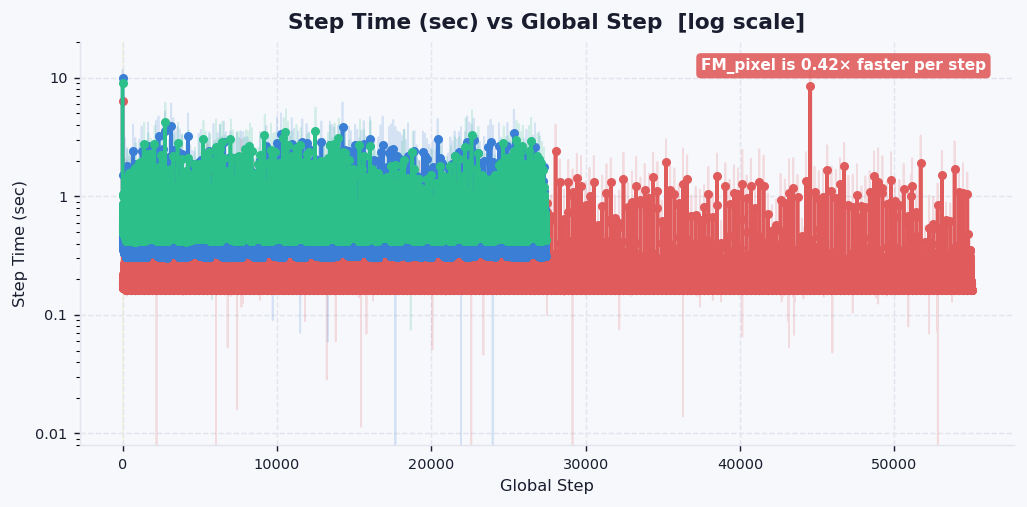

In [7]:
fig, ax = plt.subplots(figsize=(8, 4), facecolor=BG)

for label, dfs in DATA.items():
    df = dfs["step"]
    if df is None:
        continue
    color = PALETTE[label]
    a = agg(df, "global_step", "step_time_sec")
    ribbon(ax, a["global_step"], a["mean"], a["std"], color, label=label)

ax.axvspan(0.5, WARMUP_STEPS + 0.5, color="gold", alpha=0.12, zorder=1, label="warm-up")
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.2g}"))
style_ax(ax, "Step Time (sec) vs Global Step  [log scale]",
         "Global Step", "Step Time (sec)")
#ax.legend(fontsize=8.5, framealpha=0.9, edgecolor=GRID)

# ratio annotation (first two models)
labels = list(DATA.keys())
if len(labels) >= 2:
    ref, cmp = labels[0], labels[1]
    df_r = steady(DATA[ref]["step"])
    df_c = steady(DATA[cmp]["step"])
    if df_r is not None and df_c is not None:
        r = mean_val(df_r, "global_step", "step_time_sec") /             mean_val(df_c, "global_step", "step_time_sec")
        annotate_ratio(ax, f"{ref} is {r:.2f}× {'slower' if r>1 else 'faster'} per step",
                       good=(r > 1))

plt.tight_layout()
#plt.savefig("panel_step_time.png", bbox_inches="tight", facecolor=BG)
plt.show()


### 5b — Step-level throughput (samples/sec)

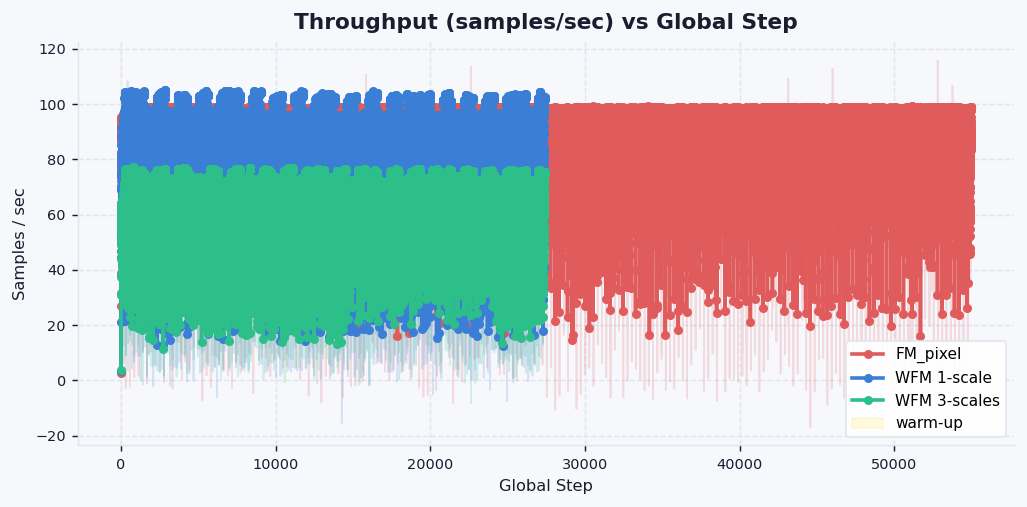

In [8]:
fig, ax = plt.subplots(figsize=(8, 4), facecolor=BG)

for label, dfs in DATA.items():
    df = dfs["step"]
    if df is None:
        continue
    a = agg(df, "global_step", "samples_per_sec")
    ribbon(ax, a["global_step"], a["mean"], a["std"], PALETTE[label], label=label)

ax.axvspan(0.5, WARMUP_STEPS + 0.5, color="gold", alpha=0.12, zorder=1, label="warm-up")
style_ax(ax, "Throughput (samples/sec) vs Global Step",
         "Global Step", "Samples / sec")
ax.legend(fontsize=8.5, framealpha=0.9, edgecolor=GRID)
plt.tight_layout()
#plt.savefig("panel_step_throughput.png", bbox_inches="tight", facecolor=BG)
plt.show()


### 5c — Epoch time (sec)

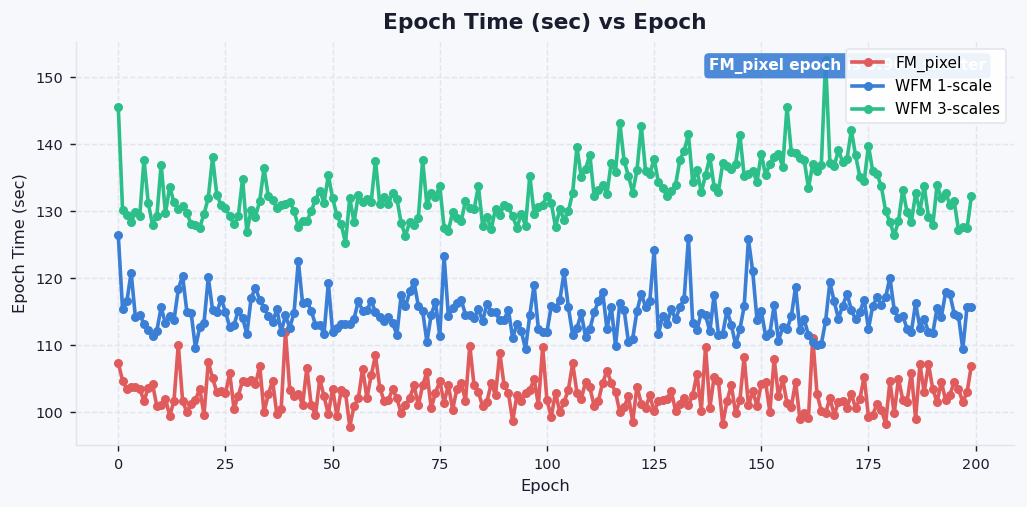

In [11]:
fig, ax = plt.subplots(figsize=(8, 4), facecolor=BG)

for label, dfs in DATA.items():
    df = dfs["epoch"]
    if df is None:
        continue
    a = agg(df, "epoch", "epoch_time_sec")
    ribbon(ax, a["epoch"], a["mean"], a["std"], PALETTE[label], label=label)

style_ax(ax, "Epoch Time (sec) vs Epoch", "Epoch", "Epoch Time (sec)")
ax.legend(fontsize=8.5, framealpha=0.9, edgecolor=GRID)

if len(labels) >= 2:
    t_r = mean_val(DATA[ref]["epoch"], "epoch", "epoch_time_sec")
    t_c = mean_val(DATA[cmp]["epoch"], "epoch", "epoch_time_sec")
    if not (np.isnan(t_r) or np.isnan(t_c)):
        r = t_r / t_c
        annotate_ratio(ax, f"{ref} epoch is {r:.2f}× {'longer' if r>1 else 'shorter'}",
                       good=(r < 1))

plt.tight_layout()
#plt.savefig("panel_epoch_time.png", bbox_inches="tight", facecolor=BG)
plt.show()


### 5d — Epoch-level throughput (samples/sec)

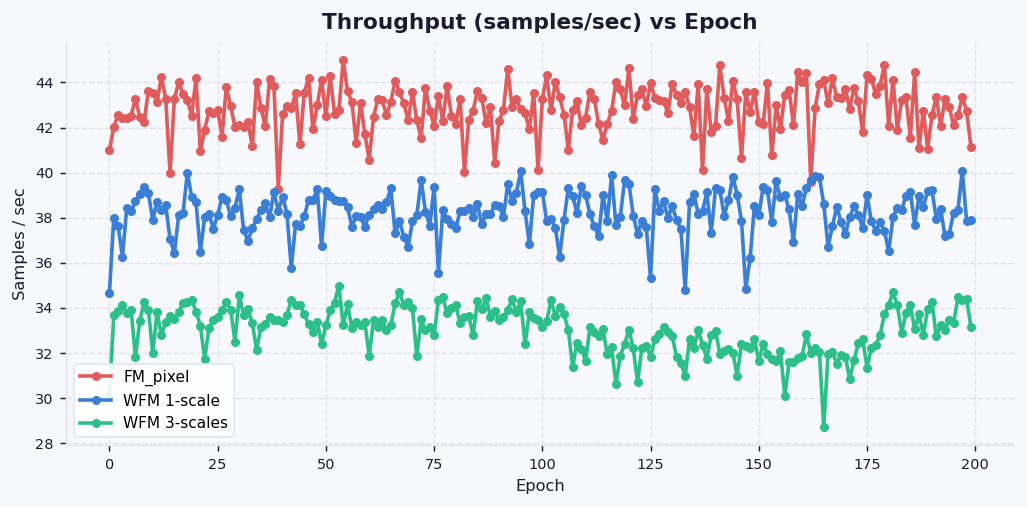

In [12]:
fig, ax = plt.subplots(figsize=(8, 4), facecolor=BG)

for label, dfs in DATA.items():
    df = dfs["epoch"]
    if df is None:
        continue
    a = agg(df, "epoch", "samples_per_sec")
    ribbon(ax, a["epoch"], a["mean"], a["std"], PALETTE[label], label=label)

style_ax(ax, "Throughput (samples/sec) vs Epoch", "Epoch", "Samples / sec")
ax.legend(fontsize=8.5, framealpha=0.9, edgecolor=GRID)
plt.tight_layout()
#plt.savefig("panel_epoch_throughput.png", bbox_inches="tight", facecolor=BG)
plt.show()


### 5e — GPU memory (GB)  *(skipped if files are absent)*

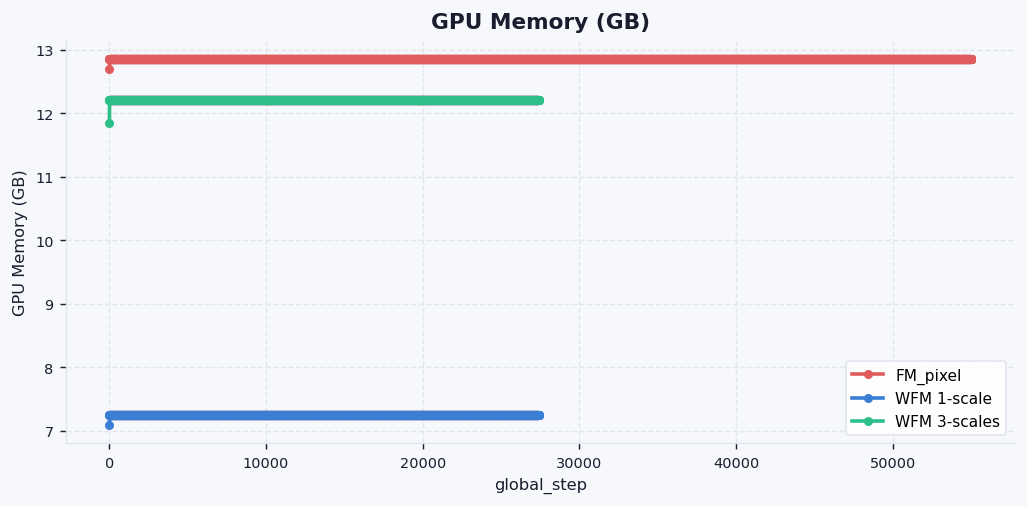

In [13]:
has_gpu = any(dfs["gpu"] is not None for dfs in DATA.values())

if has_gpu:
    fig, ax = plt.subplots(figsize=(8, 4), facecolor=BG)
    for label, dfs in DATA.items():
        df = dfs["gpu"]
        if df is None:
            continue
        x_col = df.columns[0]   # global_step or epoch
        a = agg(df, x_col, "gpu_memory_gb")
        ribbon(ax, a[x_col], a["mean"], a["std"], PALETTE[label], label=label)
    style_ax(ax, "GPU Memory (GB)", df.columns[0], "GPU Memory (GB)")
    ax.legend(fontsize=8.5, framealpha=0.9, edgecolor=GRID)
    plt.tight_layout()
    plt.savefig("panel_gpu.png", bbox_inches="tight", facecolor=BG)
    plt.show()
else:
    print("No GPU memory files found — skipping this panel.")


### 5f — Speed-up bar chart (FM / WFM step-time ratio per step)

In [ ]:
if len(labels) >= 2:
    ref_df = steady(DATA[ref]["step"])
    cmp_df = steady(DATA[cmp]["step"])

    if ref_df is not None and cmp_df is not None:
        ref_agg = agg(ref_df, "global_step", "step_time_sec")
        cmp_agg = agg(cmp_df, "global_step", "step_time_sec")

        # align on common steps
        merged = ref_agg.merge(cmp_agg, on="global_step", suffixes=("_ref", "_cmp"))
        speedup = merged["mean_ref"] / merged["mean_cmp"]
        step_labels = [f"Step {s}" for s in merged["global_step"]]

        # epoch ratios
        ep_ratios, ep_labels = [], []
        ref_ep = DATA[ref]["epoch"]
        cmp_ep = DATA[cmp]["epoch"]
        if ref_ep is not None and cmp_ep is not None:
            r_ep = agg(ref_ep, "epoch", "epoch_time_sec")
            c_ep = agg(cmp_ep, "epoch", "epoch_time_sec")
            m = r_ep.merge(c_ep, on="epoch", suffixes=("_ref", "_cmp"))
            ep_ratios = (m["mean_ref"] / m["mean_cmp"]).tolist()
            ep_labels = [f"Epoch {e}" for e in m["epoch"]]

        all_labels = step_labels + ep_labels
        all_vals   = list(speedup) + ep_ratios
        colors     = ["#3A7FD5" if v >= 1 else "#E05C5C" for v in all_vals]
        separators = [len(step_labels)]   # vertical line between steps and epochs

        fig, ax = plt.subplots(figsize=(9, max(4, 0.45 * len(all_labels) + 1.5)),
                               facecolor=BG)
        y = np.arange(len(all_labels))
        bars = ax.barh(y, all_vals, color=colors, edgecolor="none", height=0.55, zorder=3)
        ax.axvline(1.0, color=TEXT, lw=1.2, ls="--", zorder=4, alpha=0.55, label="parity (1×)")
        for bar, v in zip(bars, all_vals):
            ax.text(v + 0.01 * max(all_vals), bar.get_y() + bar.get_height() / 2,
                    f"{v:.2f}×", va="center", fontsize=8, color=TEXT)
        # separator between steps and epochs
        if ep_labels:
            ax.axhline(len(step_labels) - 0.5, color=GRID, lw=1.2, ls=":")
            ax.text(max(all_vals) * 1.01, len(step_labels) - 0.5,
                    "▲ steps  /  epochs ▼", va="center", fontsize=7.5, color=TEXT, alpha=0.7)

        ax.set_yticks(y)
        ax.set_yticklabels(all_labels, fontsize=8.5)
        ax.set_xlim(0, max(all_vals) * 1.22)
        style_ax(ax,
                 f"Speed-up factor  ({ref} time) / ({cmp} time)\n"
                 f"  > 1 → {ref} is slower  |  < 1 → {ref} is faster",
                 "Ratio", "")
        ax.legend(fontsize=8.5, framealpha=0.9, edgecolor=GRID)
        plt.tight_layout()
        #plt.savefig("panel_speedup.png", bbox_inches="tight", facecolor=BG)
        plt.show()
    else:
        print("Need step data for both models to draw this panel.")
else:
    print("Need at least two models to compare.")


---
## ⑥ Combined dashboard figure


In [ ]:
has_gpu_data = any(dfs["gpu"] is not None for dfs in DATA.values())
n_rows = 3 + int(has_gpu_data)

fig = plt.figure(figsize=(16, 5.2 * n_rows), facecolor=BG)
fig.suptitle(
    "Efficiency comparison: " + "  vs  ".join(MODELS.keys()),
    fontsize=15, fontweight="bold", color=TEXT, y=1.005,
)
gs = gridspec.GridSpec(n_rows, 2, figure=fig,
                       hspace=0.42, wspace=0.30,
                       left=0.07, right=0.97, top=0.97, bottom=0.03)

axes = {
    "step_time":       fig.add_subplot(gs[0, 0]),
    "step_throughput": fig.add_subplot(gs[0, 1]),
    "epoch_time":      fig.add_subplot(gs[1, 0]),
    "epoch_throughput":fig.add_subplot(gs[1, 1]),
    "speedup":         fig.add_subplot(gs[2, 0]),
    "table":           fig.add_subplot(gs[2, 1]),
}
if has_gpu_data:
    axes["gpu"] = fig.add_subplot(gs[3, :])


# ── step time ──────────────────────────────────────────────────────────────
ax = axes["step_time"]
for label, dfs in DATA.items():
    df = dfs["step"]
    if df is None: continue
    a = agg(df, "global_step", "step_time_sec")
    ribbon(ax, a["global_step"], a["mean"], a["std"], PALETTE[label], label=label)
ax.axvspan(0.5, WARMUP_STEPS + 0.5, color="gold", alpha=0.12, zorder=1)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"{v:.2g}"))
style_ax(ax, "Step Time (sec)  [log]", "Global Step", "Step Time (sec)")
ax.legend(fontsize=8, framealpha=0.9, edgecolor=GRID)


# ── step throughput ────────────────────────────────────────────────────────
ax = axes["step_throughput"]
for label, dfs in DATA.items():
    df = dfs["step"]
    if df is None: continue
    a = agg(df, "global_step", "samples_per_sec")
    ribbon(ax, a["global_step"], a["mean"], a["std"], PALETTE[label], label=label)
ax.axvspan(0.5, WARMUP_STEPS + 0.5, color="gold", alpha=0.12, zorder=1)
style_ax(ax, "Step Throughput (smp/s)", "Global Step", "Samples / sec")
ax.legend(fontsize=8, framealpha=0.9, edgecolor=GRID)


# ── epoch time ─────────────────────────────────────────────────────────────
ax = axes["epoch_time"]
for label, dfs in DATA.items():
    df = dfs["epoch"]
    if df is None: continue
    a = agg(df, "epoch", "epoch_time_sec")
    ribbon(ax, a["epoch"], a["mean"], a["std"], PALETTE[label], label=label)
style_ax(ax, "Epoch Time (sec)", "Epoch", "Epoch Time (sec)")
ax.legend(fontsize=8, framealpha=0.9, edgecolor=GRID)


# ── epoch throughput ───────────────────────────────────────────────────────
ax = axes["epoch_throughput"]
for label, dfs in DATA.items():
    df = dfs["epoch"]
    if df is None: continue
    a = agg(df, "epoch", "samples_per_sec")
    ribbon(ax, a["epoch"], a["mean"], a["std"], PALETTE[label], label=label)
style_ax(ax, "Epoch Throughput (smp/s)", "Epoch", "Samples / sec")
ax.legend(fontsize=8, framealpha=0.9, edgecolor=GRID)


# ── speed-up bar ───────────────────────────────────────────────────────────
ax = axes["speedup"]
if len(labels) >= 2:
    ref_df = steady(DATA[ref]["step"])
    cmp_df = steady(DATA[cmp]["step"])
    if ref_df is not None and cmp_df is not None:
        ref_agg = agg(ref_df, "global_step", "step_time_sec")
        cmp_agg = agg(cmp_df, "global_step", "step_time_sec")
        merged = ref_agg.merge(cmp_agg, on="global_step", suffixes=("_ref", "_cmp"))
        speedup = merged["mean_ref"] / merged["mean_cmp"]
        bar_labels = [f"Step {s}" for s in merged["global_step"]]
        ep_r, ep_l = [], []
        if DATA[ref]["epoch"] is not None and DATA[cmp]["epoch"] is not None:
            r_ep = agg(DATA[ref]["epoch"], "epoch", "epoch_time_sec")
            c_ep = agg(DATA[cmp]["epoch"], "epoch", "epoch_time_sec")
            m = r_ep.merge(c_ep, on="epoch", suffixes=("_ref", "_cmp"))
            ep_r = (m["mean_ref"] / m["mean_cmp"]).tolist()
            ep_l = [f"Epoch {e}" for e in m["epoch"]]
        all_l = bar_labels + ep_l
        all_v = list(speedup) + ep_r
        bar_colors = ["#3A7FD5" if v >= 1 else "#E05C5C" for v in all_v]
        y = np.arange(len(all_l))
        bars = ax.barh(y, all_v, color=bar_colors, edgecolor="none", height=0.55, zorder=3)
        ax.axvline(1.0, color=TEXT, lw=1.1, ls="--", zorder=4, alpha=0.55)
        for bar, v in zip(bars, all_v):
            ax.text(v + 0.01 * max(all_v), bar.get_y() + bar.get_height() / 2,
                    f"{v:.2f}×", va="center", fontsize=7.5, color=TEXT)
        if ep_l:
            ax.axhline(len(bar_labels) - 0.5, color=GRID, lw=1.1, ls=":")
        ax.set_yticks(y); ax.set_yticklabels(all_l, fontsize=8)
        ax.set_xlim(0, max(all_v) * 1.25)
        style_ax(ax, f"Speed-up  ({ref}) / ({cmp})", "Ratio (>1 → ref is slower)", "")
ax.set_facecolor(BG)


# ── summary table ─────────────────────────────────────────────────────────
ax = axes["table"]
ax.axis("off")
ax.set_facecolor(BG)
ax.set_title("Summary (steady-state)", fontsize=12, fontweight="bold",
             color=TEXT, pad=7)

col_headers = ["Metric"] + list(MODELS.keys())
rows_data = []
metrics = [
    ("Step time (s)",           "step",  "step_time_sec",   "global_step"),
    ("Step throughput (smp/s)", "step",  "samples_per_sec", "global_step"),
    ("Epoch time (s)",          "epoch", "epoch_time_sec",  "epoch"),
    ("Epoch throughput (smp/s)","epoch", "samples_per_sec", "epoch"),
]
for m_name, kind, val_col, key_col in metrics:
    row = [m_name]
    for label in MODELS:
        df = DATA[label][kind]
        v = mean_val(df, key_col, val_col,
                     warmup=WARMUP_STEPS if kind == "step" else None)
        row.append(f"{v:.3f}" if not np.isnan(v) else "—")
    rows_data.append(row)

all_rows = [col_headers] + rows_data
n_cols = len(col_headers)
col_x  = np.linspace(0.01, 0.99, n_cols)
n_table_rows = len(all_rows)
row_h = 1.0 / n_table_rows

for r_i, row in enumerate(all_rows):
    y_pos = 1 - (r_i + 0.55) * row_h
    for c_i, cell in enumerate(row):
        weight = "bold" if r_i == 0 or c_i == 0 else "normal"
        ax.text(col_x[c_i], y_pos, cell,
                transform=ax.transAxes, va="center",
                ha="left" if c_i == 0 else "center",
                fontsize=8.5, fontweight=weight, color=TEXT)
    if r_i < n_table_rows - 1:
        yline = 1 - (r_i + 1) * row_h
        ax.plot([0, 1], [yline, yline], color=GRID, lw=0.7, transform=ax.transAxes)

# ── GPU panel ──────────────────────────────────────────────────────────────
if has_gpu_data:
    ax = axes["gpu"]
    for label, dfs in DATA.items():
        df = dfs["gpu"]
        if df is None: continue
        x_col = df.columns[0]
        a = agg(df, x_col, "gpu_memory_gb")
        ribbon(ax, a[x_col], a["mean"], a["std"], PALETTE[label], label=label)
    style_ax(ax, "GPU Memory (GB)", x_col, "GPU Memory (GB)")
    ax.legend(fontsize=8, framealpha=0.9, edgecolor=GRID)

#plt.savefig(OUT_FIG, dpi=160, bbox_inches="tight", facecolor=BG)
print(f"\n✓ Dashboard saved → {OUT_FIG}")
plt.show()

---
## ⑦ Numerical summary table


In [9]:
rows = []
for label in MODELS:
    dfs = DATA[label]
    st_df = steady(dfs["step"]) if dfs["step"] is not None else None
    rows.append({
        "Model":                    label,
        "Avg step time (s)":        mean_val(st_df, "global_step", "step_time_sec"),
        "Avg step throughput":      mean_val(st_df, "global_step", "samples_per_sec"),
        "Avg epoch time (s)":       mean_val(dfs["epoch"], "epoch", "epoch_time_sec"),
        "Avg epoch throughput":     mean_val(dfs["epoch"], "epoch", "samples_per_sec"),
    })

summary = pd.DataFrame(rows).set_index("Model")

# add ratio row (first model vs second)
if len(labels) >= 2:
    rat = summary.loc[ref] / summary.loc[cmp]
    rat.name = f"Ratio  {ref} / {cmp}"
    summary = pd.concat([summary, rat.to_frame().T])

display(summary.style
        .format("{:.4f}", na_rep="—")
        .set_caption("Efficiency summary — steady-state averages")
        .background_gradient(axis=0, cmap="RdYlGn_r",
                              subset=["Avg step time (s)", "Avg epoch time (s)"])
        .background_gradient(axis=0, cmap="RdYlGn",
                              subset=["Avg step throughput", "Avg epoch throughput"]))


,Avg step time (s),Avg step throughput,Avg epoch time (s),Avg epoch throughput
FM_pixel,0.2005,82.8634,102.7690,42.8407
WFM 1-scale,0.4742,73.7093,114.7697,38.2227
WFM 3-scales,0.5561,60.4216,132.8775,33.0250
Ratio FM_pixel / WFM 1-scale,0.4229,1.1242,0.8954,1.1208


---
## ⑧ Export individual panels
All panels are already saved as PNG files in the working directory.  
Change `fmt` below to `"pdf"` for vector output.


In [ ]:
# Re-save all panel PNGs at higher DPI for a paper / report
fmt = "png"   # change to "pdf" for vector
for fname in ["panel_step_time", "panel_step_throughput",
              "panel_epoch_time", "panel_epoch_throughput",
              "panel_speedup", "panel_gpu", "efficiency_analysis"]:
    p = Path(f"{fname}.png")
    if p.exists():
        print(f"  {p}")
    else:
        print(f"  {fname}.{fmt}  [not generated — data missing]")


In [21]:
from datetime import datetime
import numpy as np

# ── HARDWARE FINGERPRINT — edit to match your cluster ────────────────────────
GPU_HARDWARE = {
    "GPU model":             "NVIDIA A100 80 GB SXM4",
    "# GPUs (training)":     4,
    "# GPUs (inference)":    4,
    "CUDA version":          "12.1",
    "PyTorch version":       "2.2.0",
}

# ── INFERENCE TIMESTAMPS — paste your actual start/end times ─────────────────
# Format: "Day Mon DD HH:MM:SS AM/PM TZ YYYY"
_FMT = "%a %b %d %I:%M:%S %p MDT %Y"

INFERENCE_TIMESTAMPS = {
    "FM (pixel space)": {
        "start": "Thu Apr 16 03:09:32 PM MDT 2026",
        "end":   "Thu Apr 16 03:49:17 PM MDT 2026",
    },
    "WFM 1-scale": {
        "start": "Thu Apr 16 03:41:23 PM MDT 2026",
        "end":   "Thu Apr 16 04:18:10 PM MDT 2026",
    },
    "WFM 3-scales": {
        "start": None,   # ← fill in when available
        "end":   None,
    },
}

ROLLOUT_STEPS   = 196
EULER_STEPS     = 50
INFERENCE_NFE   = ROLLOUT_STEPS * EULER_STEPS   # 9 800
INFERENCE_NGPU  = 4

def _infer_sec(label):
    info = INFERENCE_TIMESTAMPS.get(label, {})
    if not info.get("start") or not info.get("end"):
        return float("nan")
    return (datetime.strptime(info["end"],   _FMT) -
            datetime.strptime(info["start"], _FMT)).total_seconds()

# ── print hardware card ────────────────────────────────────────────────────────
print("Hardware fingerprint")
print("─" * 50)
for k, v in GPU_HARDWARE.items():
    print(f"  {k:<28s}: {v}")
print(f"\nInference setup")
print("─" * 50)
print(f"  Rollout steps          : {ROLLOUT_STEPS}")
print(f"  Euler steps / rollout  : {EULER_STEPS}")
print(f"  Total NFEs             : {INFERENCE_NFE:,}")
print(f"  GPUs                   : {INFERENCE_NGPU}")


Hardware fingerprint
──────────────────────────────────────────────────
  GPU model                   : NVIDIA A100 80 GB SXM4
  # GPUs (training)           : 4
  # GPUs (inference)          : 4
  CUDA version                : 12.1
  PyTorch version             : 2.2.0

Inference setup
──────────────────────────────────────────────────
  Rollout steps          : 196
  Euler steps / rollout  : 50
  Total NFEs             : 9,800
  GPUs                   : 4


In [22]:
import pandas as pd

rows = []

for label in MODELS:
    dfs   = DATA[label]
    st_df = steady(dfs["step"])  if dfs["step"]  is not None else None
    ep_df = dfs["epoch"]
    gp_df = dfs["gpu"]

    # ── step-level (steady-state) ──────────────────────────────────────────────
    avg_step_time  = mean_val(st_df, "global_step", "step_time_sec")
    avg_step_tput  = mean_val(st_df, "global_step", "samples_per_sec")

    # ── epoch-level ────────────────────────────────────────────────────────────
    avg_epoch_time = mean_val(ep_df, "epoch", "epoch_time_sec")
    avg_epoch_tput = mean_val(ep_df, "epoch", "samples_per_sec")

    # ── derived: steps per epoch ──────────────────────────────────────────────
    # = epoch_time / step_time  (how many gradient steps fit in one epoch)
    # WFM should be ~½ of FM because the compressed space → fewer batches
    steps_per_epoch = (
        avg_epoch_time / avg_step_time
        if not np.isnan(avg_epoch_time) and not np.isnan(avg_step_time) and avg_step_time > 0
        else float("nan")
    )

    # ── GPU memory ─────────────────────────────────────────────────────────────
    if gp_df is not None and "gpu_memory_gb" in gp_df.columns:
        avg_gpu_mem  = gp_df["gpu_memory_gb"].mean()
        peak_gpu_mem = gp_df["gpu_memory_gb"].max()
    else:
        avg_gpu_mem  = float("nan")
        peak_gpu_mem = float("nan")

    # ── inference ──────────────────────────────────────────────────────────────
    infer_sec    = _infer_sec(label)
    infer_min    = infer_sec / 60
    time_per_nfe = infer_sec / INFERENCE_NFE

    rows.append({
        "Model":                    label,
        # step
        "Step time (s)":            avg_step_time,
        "Step throughput (smp/s)":  avg_step_tput,
        "Steps / epoch ↓":          steps_per_epoch,
        # epoch
        "Epoch time (s)":           avg_epoch_time,
        "Epoch throughput (smp/s)": avg_epoch_tput,
        # memory
        "Avg GPU mem (GB)":         avg_gpu_mem,
        "Peak GPU mem (GB)":        peak_gpu_mem,
        # inference
        "Inference time (min)":     infer_min,
        "Time / NFE (s)":           time_per_nfe,
    })

summary = pd.DataFrame(rows).set_index("Model")

# ── ratio rows: FM / each WFM variant ─────────────────────────────────────────
_ref = labels[0]
ratio_frames = []
for _cmp in labels[1:]:
    rat      = summary.loc[_ref] / summary.loc[_cmp]
    rat.name = f"Ratio  {_ref} / {_cmp}"
    ratio_frames.append(rat.to_frame().T)

summary_full = pd.concat([summary] + ratio_frames)

# ── amortisation analysis (console) ───────────────────────────────────────────
print("Overhead amortisation")
print("─" * 65)
print(f"  {'Model':<20s}  {'Step OH':>8s}  {'Epoch OH':>9s}  {'Amort ratio':>12s}  {'Status':>6s}")
print("─" * 65)
for _cmp in labels[1:]:
    s_oh   = summary.loc[_cmp, "Step time (s)"]  / summary.loc[_ref, "Step time (s)"]
    e_oh   = summary.loc[_cmp, "Epoch time (s)"] / summary.loc[_ref, "Epoch time (s)"]
    amort  = s_oh / e_oh if e_oh > 0 else float("nan")
    status = "✓ amortised" if amort > 1 else "✗ not amortised"
    print(f"  {_cmp:<20s}  {s_oh:>7.2f}×  {e_oh:>8.2f}×  {amort:>11.2f}×  {status}")
print("─" * 65)
print("  Amort ratio > 1 → step overhead is partially recovered at epoch level.")
print("  This happens because WFM processes fewer batches per epoch")
print("  (wavelet compression reduces the number of steps needed to")
print("  traverse the full dataset).")


Overhead amortisation
─────────────────────────────────────────────────────────────────
  Model                  Step OH   Epoch OH   Amort ratio  Status
─────────────────────────────────────────────────────────────────
  WFM 1-scale              2.36×      1.12×         2.12×  ✓ amortised
  WFM 3-scales             2.77×      1.29×         2.14×  ✓ amortised
─────────────────────────────────────────────────────────────────
  Amort ratio > 1 → step overhead is partially recovered at epoch level.
  This happens because WFM processes fewer batches per epoch
  (wavelet compression reduces the number of steps needed to
  traverse the full dataset).


In [23]:
_model_rows  = list(MODELS.keys())
_ratio_names = [f"Ratio  {labels[0]} / {c}" for c in labels[1:]]

# columns where LOWER is better (red = high = bad)
_lower_better = [
    "Step time (s)", "Steps / epoch ↓",
    "Epoch time (s)",
    "Avg GPU mem (GB)", "Peak GPU mem (GB)",
    "Inference time (min)", "Time / NFE (s)",
]
# columns where HIGHER is better (green = high = good)
_higher_better = [
    "Step throughput (smp/s)",
    "Epoch throughput (smp/s)",
]

_fmt = {
    "Step time (s)":            "{:.4f}",
    "Step throughput (smp/s)":  "{:.2f}",
    "Steps / epoch ↓":          "{:.1f}",
    "Epoch time (s)":           "{:.2f}",
    "Epoch throughput (smp/s)": "{:.2f}",
    "Avg GPU mem (GB)":         "{:.2f}",
    "Peak GPU mem (GB)":        "{:.2f}",
    "Inference time (min)":     "{:.2f}",
    "Time / NFE (s)":           "{:.4f}",
}

styled = (
    summary_full.style
    .format(_fmt, na_rep="—")
    .set_caption(
        f"Computational efficiency summary  |  "
        f"Training: steady-state (steps > {WARMUP_STEPS})  |  "
        f"Inference: {INFERENCE_NFE:,} NFEs ({ROLLOUT_STEPS} rollout × {EULER_STEPS} Euler), "
        f"{INFERENCE_NGPU} GPUs  |  "
        f"Hardware: {GPU_HARDWARE['GPU model']}"
    )
)

# gradients on model rows only
for col in _lower_better:
    if col in summary_full.columns:
        styled = styled.background_gradient(
            cmap="RdYlGn_r",
            subset=pd.IndexSlice[_model_rows, col],
            axis=0,
        )
for col in _higher_better:
    if col in summary_full.columns:
        styled = styled.background_gradient(
            cmap="RdYlGn",
            subset=pd.IndexSlice[_model_rows, col],
            axis=0,
        )

# style ratio rows
styled = styled.set_properties(
    subset=pd.IndexSlice[_ratio_names, :],
    **{"font-weight": "bold", "background-color": "#efefef", "color": "#1a1d2e"},
)

display(styled)


,Step time (s),Step throughput (smp/s),Steps / epoch ↓,Epoch time (s),Epoch throughput (smp/s),Avg GPU mem (GB),Peak GPU mem (GB),Inference time (min),Time / NFE (s)
FM_pixel,0.2005,82.86,512.5,102.77,42.84,12.86,12.86,—,—
WFM 1-scale,0.4742,73.71,242.0,114.77,38.22,7.25,7.25,36.78,0.2252
WFM 3-scales,0.5561,60.42,238.9,132.88,33.02,12.21,12.21,—,—
Ratio FM_pixel / WFM 1-scale,0.4229,1.12,2.1,0.90,1.12,1.77,1.77,—,—
Ratio FM_pixel / WFM 3-scales,0.3606,1.37,2.1,0.77,1.30,1.05,1.05,—,—


In [24]:
import re
from pathlib import Path
from datetime import datetime
import pandas as pd

# ── timestamp formats your script uses ───────────────────────────────────
_TS_FMTS = [
    "%a %b %d %I:%M:%S %p MDT %Y",   # Thu Apr 16 03:09:32 PM MDT 2026
    "%a %b %d %I:%M:%S %p MST %Y",
    "%a %b %d %H:%M:%S MDT %Y",       # 24-h fallback
    "%a %b %d %H:%M:%S MST %Y",
]

def _parse_ts(raw: str):
    raw = (raw or "").strip()
    for fmt in _TS_FMTS:
        try:
            return datetime.strptime(raw, fmt)
        except ValueError:
            pass
    return None

# ── regex patterns for every field we want ───────────────────────────────
_PATTERNS = {
    "job_id":         r"Job ID\s*:\s*(.+)",
    "job_name":       r"Job name\s*:\s*(.+)",
    "n_gpus":         r"GPUs\s*:\s*(\d+)",
    "n_ensemble":     r"N_ENSEMBLE\s*:\s*(\d+)",
    "num_sampling":   r"NUM_SAMPLING\s*:\s*(\d+)",
    "ode_method":     r"ODE_METHOD\s*:\s*(\S+)",
    "clamp_sigma":    r"CLAMP_SIGMA\s*:\s*(\S+)",
    "config":         r"Config\s*:\s*(.+)",
    "checkpoint":     r"Checkpoint\s*:\s*(.+)",
    "n_traj":         r"N_TRAJ\s*:\s*(\d+)",
    "_start_raw":     r"Started\s*:\s*(.+)",
    "_end_raw":       r"Finished\s*:\s*(.+)",
    "_rollout_steps": r"rollout_steps=(\d+)",
}

def parse_inference_log(path) -> dict:
    """Parse a single inference log file → dict of extracted/derived fields."""
    path = Path(path)
    if not path.exists():
        print(f"  [skip] {path} not found")
        return {"log_file": path.name, "log_path": str(path)}

    text = path.read_text(errors="replace")
    result = {"log_file": path.name, "log_path": str(path)}

    for key, pattern in _PATTERNS.items():
        m = re.search(pattern, text)
        result[key] = m.group(1).strip() if m else None

    # parse timestamps
    start_dt = _parse_ts(result.pop("_start_raw"))
    end_dt   = _parse_ts(result.pop("_end_raw"))
    result["start_time"] = start_dt
    result["end_time"]   = end_dt

    # wall-clock
    if start_dt and end_dt:
        result["wall_clock_sec"] = (end_dt - start_dt).total_seconds()
        result["wall_clock_min"] = result["wall_clock_sec"] / 60
    else:
        result["wall_clock_sec"] = result["wall_clock_min"] = None

    # rollout_steps: max across all progress lines
    all_steps = [int(x) for x in re.findall(_PATTERNS["_rollout_steps"], text)]
    result["rollout_steps"] = max(all_steps) if all_steps else None
    result.pop("_rollout_steps", None)

    # cast numeric fields
    for f in ("n_gpus", "n_ensemble", "num_sampling", "n_traj", "rollout_steps"):
        try:    result[f] = int(result[f])
        except: pass
    try:    result["clamp_sigma"] = float(result["clamp_sigma"])
    except: pass

    # derived NFE metrics
    rs, ns = result.get("rollout_steps"), result.get("num_sampling")
    wc     = result.get("wall_clock_sec")
    if rs and ns:
        result["total_nfe"]      = rs * ns
        result["sec_per_nfe"]    = wc / result["total_nfe"] if wc else None
        result["sec_per_rollout"]= wc / rs                  if wc else None
    else:
        result["total_nfe"] = result["sec_per_nfe"] = result["sec_per_rollout"] = None

    return result


def parse_inference_logs(paths) -> pd.DataFrame:
    """Parse multiple log files → tidy DataFrame (one row per file)."""
    records = [parse_inference_log(p) for p in paths]
    df = pd.DataFrame(records)
    if "start_time" in df.columns:
        df = df.sort_values("start_time").reset_index(drop=True)
    return df

print("Parser ready.  Use parse_inference_log(path) or parse_inference_logs([...]).")


Parser ready.  Use parse_inference_log(path) or parse_inference_logs([...]).


In [28]:
ROOT = '/Users/gabrieleaccarino/Workspace/waveletflux/performance'

PDE = "rayleigh_benard"

# ── CONFIGURE: map model labels to log file paths ────────────────────────
INFERENCE_LOGS = {
    "FM"            : f"{ROOT}/{PDE}/inference/FM.out",
    "WFM 1-scale"   : f"{ROOT}/{PDE}/inference/WFM1.out",
    "WFM 3-scales"  : f"{ROOT}/{PDE}/inference/WFM3.out",
}

# ── parse ─────────────────────────────────────────────────────────────────
rows = []
for model_label, log_path in INFERENCE_LOGS.items():
    rec = parse_inference_log(log_path)
    rec["model"] = model_label
    rows.append(rec)

timing_df = pd.DataFrame(rows).set_index("model") if rows else pd.DataFrame()

# ── display key columns ────────────────────────────────────────────────────
DISPLAY_COLS = [
    "job_id", "job_name", "n_gpus", "n_ensemble",
    "num_sampling", "rollout_steps", "total_nfe",
    "start_time", "end_time",
    "wall_clock_sec", "wall_clock_min",
    "sec_per_nfe", "sec_per_rollout",
]

if not timing_df.empty:
    display(timing_df[[c for c in DISPLAY_COLS if c in timing_df.columns]]
            .style
            .format({
                "wall_clock_sec":  "{:.1f}",
                "wall_clock_min":  "{:.2f}",
                "sec_per_nfe":     "{:.4f}",
                "sec_per_rollout": "{:.3f}",
            }, na_rep="—")
            .set_caption("Inference timing — parsed from log files"))


,job_id,job_name,n_gpus,n_ensemble,num_sampling,rollout_steps,total_nfe,start_time,end_time,wall_clock_sec,wall_clock_min,sec_per_nfe,sec_per_rollout
model,,,,,,,,,,,,,
FM,5847674.desched1,FM_data_space_v4.0_rayleigh_benard_inference,4,8,50,196,9800,2026-04-16 15:09:32,2026-04-16 15:49:17,2385.0,39.75,0.2434,12.168
WFM 1-scale,5847342.desched1,WaveletFlow_1scale_db2_v4.0_rayleigh_benard_inference,4,8,50,196,9800,2026-04-16 14:51:23,2026-04-16 15:27:14,2151.0,35.85,0.2195,10.974
WFM 3-scales,5848008.desched1,WaveletFlow_3scales_db2_v4.0_rayleigh_benard_inference,4,8,50,196,9800,2026-04-16 15:41:23,2026-04-16 16:18:10,2207.0,36.78,0.2252,11.260


In [26]:
if len(timing_df) >= 2:
    labels   = list(timing_df.index)
    ref, cmp = labels[0], labels[1]

    metric_cols = ["wall_clock_sec", "wall_clock_min", "sec_per_nfe", "sec_per_rollout"]
    comp = timing_df[metric_cols].copy()

    rat = comp.loc[ref] / comp.loc[cmp]
    rat.name = f"Ratio  {ref} / {cmp}"
    comp = pd.concat([comp, rat.to_frame().T])

    # print metadata block
    r = timing_df.iloc[0]
    print(f"Hardware / run metadata (from {labels[0]} log):")
    print(f"  Job         : {r.get('job_name', '—')}")
    print(f"  Rollout steps  : {r.get('rollout_steps', '—')}")
    print(f"  Euler steps    : {r.get('num_sampling', '—')}")
    print(f"  Total NFEs     : {int(r['total_nfe']):,}" if r.get('total_nfe') else "  Total NFEs     : —")
    print(f"  GPUs           : {r.get('n_gpus', '—')}")
    print(f"  Ensemble size  : {r.get('n_ensemble', '—')}")
    print(f"  ODE method     : {r.get('ode_method', '—')}")
    print()

    # styled table
    styled = (comp.style
              .format("{:.4f}", na_rep="—")
              .set_caption(
                  f"Inference efficiency  |  "
                  f"ratio > 1 means {ref} is slower  |  "
                  f"ratio < 1 means {ref} is faster")
              .set_properties(
                  subset=pd.IndexSlice[[rat.name], :],
                  **{"font-weight": "bold", "background-color": "#efefef"}))

    # colour: ratio > 1 (FM slower → good for WFM) in blue, < 1 in red
    def colour_ratio(v):
        if isinstance(v, float):
            return f"color: {'#3A7FD5' if v >= 1 else '#E05C5C'}; font-weight: bold"
        return ""
    styled = styled.applymap(colour_ratio, subset=pd.IndexSlice[[rat.name], :])
    display(styled)

    wc_r = timing_df.loc[ref, "wall_clock_min"]
    wc_c = timing_df.loc[cmp, "wall_clock_min"]
    nfe_r = timing_df.loc[ref, "sec_per_nfe"]
    nfe_c = timing_df.loc[cmp, "sec_per_nfe"]
    if wc_r and wc_c:
        print(f"\n→ {cmp} completes inference in {wc_c:.2f} min vs {wc_r:.2f} min for {ref}")
        print(f"  Wall-clock ratio: {wc_r/wc_c:.3f}×  ({abs(1-wc_r/wc_c)*100:.1f}% {'faster' if wc_c < wc_r else 'slower'})")
    if nfe_r and nfe_c:
        print(f"  Per-NFE ratio:    {nfe_r/nfe_c:.3f}×")
else:
    print("Need at least two log files to compute a ratio.")


Hardware / run metadata (from FM log):
  Job         : FM_data_space_v4.0_rayleigh_benard_inference
  Rollout steps  : 196
  Euler steps    : 50
  Total NFEs     : 9,800
  GPUs           : 4
  Ensemble size  : 8
  ODE method     : euler



,wall_clock_sec,wall_clock_min,sec_per_nfe,sec_per_rollout
FM,2385.0000,39.7500,0.2434,12.1684
WFM 1-scale,2151.0000,35.8500,0.2195,10.9745
WFM 3-scales,2207.0000,36.7833,0.2252,11.2602
Ratio FM / WFM 1-scale,1.1088,1.1088,1.1088,1.1088



→ WFM 1-scale completes inference in 35.85 min vs 39.75 min for FM
  Wall-clock ratio: 1.109×  (10.9% faster)
  Per-NFE ratio:    1.109×


In [27]:
print(comp.to_latex(float_format="%.3f"))

\begin{tabular}{lrrrr}
\toprule
 & wall_clock_sec & wall_clock_min & sec_per_nfe & sec_per_rollout \\
\midrule
FM & 2385.000 & 39.750 & 0.243 & 12.168 \\
WFM 1-scale & 2151.000 & 35.850 & 0.219 & 10.974 \\
WFM 3-scales & 2207.000 & 36.783 & 0.225 & 11.260 \\
Ratio  FM / WFM 1-scale & 1.109 & 1.109 & 1.109 & 1.109 \\
\bottomrule
\end{tabular}



In [38]:
import re
import itertools
import pandas as pd
from datetime import datetime
from IPython.display import display
 
# ── strip the timezone abbreviation before parsing (MDT, UTC, etc.)
# Python's strptime does not reliably handle named TZ abbreviations on all
# platforms, so we remove them and parse the rest.  Both timestamps in the
# same log are always in the same TZ, so the delta is still correct.
_TIME_FMT = "%a %b %d %I:%M:%S %p %Y"
_TZ_RE    = re.compile(r"\s+[A-Z]{2,5}(?=\s+\d{4})")
 
 
def _parse_ts(raw: str) -> datetime | None:
    """Strip TZ abbreviation and parse the remaining timestamp string."""
    if not raw:
        return None
    cleaned = _TZ_RE.sub("", raw).strip()
    try:
        return datetime.strptime(cleaned, _TIME_FMT)
    except ValueError:
        return None
 
 
# ─────────────────────────────────────────────────────────────────────────────
 
def parse_inference_log(log_path: str) -> dict:
    """
    Parse a single inference .out log file and return a flat dict of metrics.
 
    Extracted fields
    ----------------
    job_id, job_name, n_gpus, n_ensemble, num_sampling, ode_method,
    start_time (raw str), end_time (raw str),
    wall_clock_sec, wall_clock_min,
    rollout_steps, total_nfe,
    sec_per_nfe, sec_per_rollout
    """
    rec: dict = {}
 
    with open(log_path, "r", errors="replace") as fh:
        text = fh.read()
 
    # ── header fields ─────────────────────────────────────────────────────────
    patterns = {
        "job_id":       r"Job ID\s*:\s*(.+)",
        "job_name":     r"Job name\s*:\s*(.+)",
        "n_gpus":       r"GPUs\s*:\s*(\d+)",
        "n_ensemble":   r"N_ENSEMBLE\s*:\s*(\d+)",
        "num_sampling": r"NUM_SAMPLING\s*:\s*(\d+)",
        "ode_method":   r"ODE_METHOD\s*:\s*(\S+)",
        "clamp_sigma":  r"CLAMP_SIGMA\s*:\s*(\S+)",
        "start_time":   r"Started\s*:\s*(.+)",
        "end_time":     r"Finished\s*:\s*(.+)",
    }
    for key, pat in patterns.items():
        m = re.search(pat, text)
        rec[key] = m.group(1).strip() if m else None
 
    # cast numeric fields
    for key in ("n_gpus", "n_ensemble", "num_sampling"):
        if rec.get(key):
            rec[key] = int(rec[key])
 
    # ── wall-clock duration ───────────────────────────────────────────────────
    rec["wall_clock_sec"] = None
    rec["wall_clock_min"] = None
    t0 = _parse_ts(rec.get("start_time"))
    t1 = _parse_ts(rec.get("end_time"))
    if t0 and t1:
        sec = (t1 - t0).total_seconds()
        rec["wall_clock_sec"] = sec
        rec["wall_clock_min"] = sec / 60.0
 
    # ── rollout steps (max frame index seen in progress lines) ───────────────
    frame_nums = [int(m) for m in re.findall(r"rollout call\s+(\d+)/\d+", text)]
    rec["rollout_steps"] = max(frame_nums) if frame_nums else None
 
    # ── derived metrics ───────────────────────────────────────────────────────
    ns  = rec.get("num_sampling")
    rs  = rec.get("rollout_steps")
    wcs = rec.get("wall_clock_sec")
 
    rec["total_nfe"]       = ns * rs                if (ns and rs)               else None
    rec["sec_per_nfe"]     = wcs / rec["total_nfe"] if (wcs and rec["total_nfe"]) else None
    rec["sec_per_rollout"] = wcs / rs               if (wcs and rs)               else None
 
    return rec
 
 
# ─────────────────────────────────────────────────────────────────────────────
 
def build_timing_df(inference_logs: dict) -> pd.DataFrame:
    """
    Parameters
    ----------
    inference_logs : dict
        {"FM": ".../FM.out", "WFM 1-scale": ".../WFM1.out", ...}
 
    Returns
    -------
    pd.DataFrame indexed by model label.
    Missing log files are skipped with a warning.
    """
    rows = []
    for label, path in inference_logs.items():
        try:
            rec = parse_inference_log(path)
        except FileNotFoundError:
            print(f"[warn] log not found, skipping: {path}")
            continue
        rec["model"] = label
        rows.append(rec)
    return pd.DataFrame(rows).set_index("model") if rows else pd.DataFrame()
 
 
# ─────────────────────────────────────────────────────────────────────────────
 
DISPLAY_COLS = [
    "job_id", "job_name", "n_gpus", "n_ensemble",
    "num_sampling", "rollout_steps", "total_nfe",
    "start_time", "end_time",
    "wall_clock_sec", "wall_clock_min",
    "sec_per_nfe", "sec_per_rollout",
]
 
METRIC_COLS = [
    "wall_clock_sec", "wall_clock_min",
    "sec_per_nfe", "sec_per_rollout",
]
 
FORMAT_MAP = {
    "wall_clock_sec":  "{:.1f}",
    "wall_clock_min":  "{:.2f}",
    "sec_per_nfe":     "{:.4f}",
    "sec_per_rollout": "{:.3f}",
}
 
 
def _colour_ratio(v):
    """Blue when ref is slower (ratio > 1), red when ref is faster (ratio < 1)."""
    if isinstance(v, float):
        colour = "#3A7FD5" if v >= 1 else "#E05C5C"
        return f"color: {colour}; font-weight: bold"
    return ""
 
 
def show_table(timing_df: pd.DataFrame) -> None:
    """
    Display:
      1. Full metadata table for all models.
      2. Metric table with all-pairs ratio rows appended at the bottom.
      3. Plain-text summary.
    """
    if timing_df.empty:
        print("No data to display.")
        return
 
    labels      = list(timing_df.index)
    metric_cols = [c for c in METRIC_COLS if c in timing_df.columns]
 
    # ── 1. metadata table ─────────────────────────────────────────────────────
    visible = [c for c in DISPLAY_COLS if c in timing_df.columns]
    display(
        timing_df[visible]
        .style
        .format(FORMAT_MAP, na_rep="—")
        .set_caption("Inference timing — parsed from log files")
    )
 
    if len(timing_df) < 2:
        print("Need at least two models to compute ratios.")
        return
 
    # ── 2. metric values + all-pairs ratio rows ───────────────────────────────
    comp = timing_df[metric_cols].copy()
 
    ratio_names = []
    ratio_rows  = []
    for ref, cmp in itertools.combinations(labels, 2):
        rat      = comp.loc[ref] / comp.loc[cmp]
        rat_name = f"Ratio  {ref} / {cmp}"
        rat.name = rat_name
        ratio_rows.append(rat)
        ratio_names.append(rat_name)
 
    comp = pd.concat([comp, pd.DataFrame(ratio_rows)])
 
    styled = (
        comp.style
        .format("{:.4f}", na_rep="—")
        .set_caption(
            "Inference efficiency  |  "
            "ratio > 1 → numerator model is slower  |  "
            "ratio < 1 → numerator model is faster"
        )
        .set_properties(
            subset=pd.IndexSlice[ratio_names, :],
            **{"font-weight": "bold", "background-color": "#f0f0f0"},
        )
        .applymap(_colour_ratio, subset=pd.IndexSlice[ratio_names, :])
    )
    display(styled)
 
    # ── 3. plain-text summary ─────────────────────────────────────────────────
    r0  = timing_df.iloc[0]
    nfe = r0.get("total_nfe")
    print(f"\nHardware / run metadata (from '{labels[0]}' log):")
    print(f"  Job            : {r0.get('job_name', '—')}")
    print(f"  Rollout steps  : {r0.get('rollout_steps', '—')}")
    print(f"  Euler steps    : {r0.get('num_sampling', '—')}")
    print(f"  Total NFEs     : {int(nfe):,}" if nfe else "  Total NFEs     : —")
    print(f"  GPUs           : {r0.get('n_gpus', '—')}")
    print(f"  Ensemble size  : {r0.get('n_ensemble', '—')}")
    print(f"  ODE method     : {r0.get('ode_method', '—')}")
 
    print()
    for ref, cmp in itertools.combinations(labels, 2):
        wc_ref = timing_df.loc[ref, "wall_clock_min"]
        wc_cmp = timing_df.loc[cmp, "wall_clock_min"]
        if pd.isna(wc_ref) or pd.isna(wc_cmp) or not wc_ref or not wc_cmp:
            continue
        ratio  = wc_ref / wc_cmp
        faster = wc_cmp < wc_ref
        print(
            f"→ {cmp}  vs  {ref}:  "
            f"{wc_cmp:.2f} min  vs  {wc_ref:.2f} min  |  "
            f"ratio {ratio:.3f}×  "
            f"({abs(1 - ratio) * 100:.1f}% {'faster' if faster else 'slower'})"
        )
    return comp, styled

In [46]:
ROOT = "/Users/gabrieleaccarino/Workspace/waveletflux/performance"
#PDE  = "rayleigh_benard"
#PDE  = "turbulent_radiative_layer_2D"
PDE  = "active_matter"
 
INFERENCE_LOGS = {
    "FM"           : f"{ROOT}/{PDE}/inference/FM.out",
    "WFM 1-scale"  : f"{ROOT}/{PDE}/inference/WFM1.out",
    "WFM 3-scales" : f"{ROOT}/{PDE}/inference/WFM3.out",
}

timing_df = build_timing_df(INFERENCE_LOGS)
comp, _ = show_table(timing_df)

,job_id,job_name,n_gpus,n_ensemble,num_sampling,rollout_steps,total_nfe,start_time,end_time,wall_clock_sec,wall_clock_min,sec_per_nfe,sec_per_rollout
model,,,,,,,,,,,,,
FM,5848805.desched1,FM_data_space_v4.0_active_matter_inference,4,8,50,77,3850,Thu Apr 16 05:20:59 PM MDT 2026,Thu Apr 16 06:05:14 PM MDT 2026,2655.0,44.25,0.6896,34.481
WFM 1-scale,5848986.desched1,WaveletFlow_1scale_db2_v4.0_active_matter_inference,4,8,50,77,3850,Thu Apr 16 05:40:42 PM MDT 2026,Thu Apr 16 06:24:18 PM MDT 2026,2616.0,43.60,0.6795,33.974
WFM 3-scales,5849640.desched1,WaveletFlow_3scales_db2_v4.0_active_matter_inference,4,8,50,77,3850,Thu Apr 16 07:56:24 PM MDT 2026,Thu Apr 16 08:40:48 PM MDT 2026,2664.0,44.40,0.6919,34.597


,wall_clock_sec,wall_clock_min,sec_per_nfe,sec_per_rollout
FM,2655.0000,44.2500,0.6896,34.4805
WFM 1-scale,2616.0000,43.6000,0.6795,33.9740
WFM 3-scales,2664.0000,44.4000,0.6919,34.5974
Ratio FM / WFM 1-scale,1.0149,1.0149,1.0149,1.0149
Ratio FM / WFM 3-scales,0.9966,0.9966,0.9966,0.9966
Ratio WFM 1-scale / WFM 3-scales,0.9820,0.9820,0.9820,0.9820



Hardware / run metadata (from 'FM' log):
  Job            : FM_data_space_v4.0_active_matter_inference
  Rollout steps  : 77
  Euler steps    : 50
  Total NFEs     : 3,850
  GPUs           : 4
  Ensemble size  : 8
  ODE method     : euler

→ WFM 1-scale  vs  FM:  43.60 min  vs  44.25 min  |  ratio 1.015×  (1.5% faster)
→ WFM 3-scales  vs  FM:  44.40 min  vs  44.25 min  |  ratio 0.997×  (0.3% slower)
→ WFM 3-scales  vs  WFM 1-scale:  44.40 min  vs  43.60 min  |  ratio 0.982×  (1.8% slower)


In [48]:
print(comp.to_latex(float_format="%.3f"))

\begin{tabular}{lrrrr}
\toprule
 & wall_clock_sec & wall_clock_min & sec_per_nfe & sec_per_rollout \\
\midrule
FM & 2655.000 & 44.250 & 0.690 & 34.481 \\
WFM 1-scale & 2616.000 & 43.600 & 0.679 & 33.974 \\
WFM 3-scales & 2664.000 & 44.400 & 0.692 & 34.597 \\
Ratio  FM / WFM 1-scale & 1.015 & 1.015 & 1.015 & 1.015 \\
Ratio  FM / WFM 3-scales & 0.997 & 0.997 & 0.997 & 0.997 \\
Ratio  WFM 1-scale / WFM 3-scales & 0.982 & 0.982 & 0.982 & 0.982 \\
\bottomrule
\end{tabular}

